# UCAI Flagship 4 — Paper 1 (Tier-2 Upgrade): `ucai-verify v0.2.0` & Full 120-Item Hybrid Benchmark

**โครงการวิจัย:** *Zero-Fake-Citation & Cross-Document Numeric Audit Engine: Deterministic & Hybrid Verification Against AI Hallucinations in Scientific Writing*

สมุดบันทึก Google Colab รุ่น **Tier-2 (v0.2.0 — Cache-Proof)** เชื่อมต่อกับคลัง PDF จริงบน Google Drive (`UCAI-Central-Library`) เพื่อรันครบทั้ง 5 วิธีบน **120 ข้อเต็ม**:
1. **Stage 1 (`ucai-verify v0.2.0` — ฟรี `$0`):** ตรวจอ้างอิงสด (`arXiv`, `Crossref`, `OpenAlex` รองรับการเปลี่ยนชื่อ Preprint `v1->v2`) + ตรวจตัวเลขข้ามไฟล์ PDF จริง (`146,932` และ `87.4% <-> 0.874`) ครบ **120 ข้อ**
2. **Stage 2A Hybrid (`Local DeBERTa-v3 NLI` — ฟรี `$0`):** รันโมเดลเปิดตรวจการกลับขั้วความหมายเฉพาะข้อที่ผ่านด่านแรก
3. **Stage 2B Hybrid (`Scoped Gemini`) + คู่เทียบ Pure LLM ครบ 120 ข้อเต็ม:** รัน `Hybrid-Scoped-Gemini`, `Self-Critique (120 ข้อ)`, และ `LLM-as-a-Judge (120 ข้อ)` พร้อมระบบ **Auto-Checkpoint เซฟลง Google Drive ทุกๆ 5 ข้อ** และคำนวณสถิติ **95% Bootstrap CI + Exact McNemar's Test**

In [1]:
# @title 1. เชื่อมต่อ Google Drive (Force Refresh), ล้างแคชโมดูลเก่า และรวมคลัง PDF ทั้ง 4 โฟลเดอร์
import os, sys, shutil, importlib
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

!pip install -q pymupdf requests matplotlib pandas sentencepiece protobuf sentence-transformers google-genai

WORKSPACE_CANDIDATES = [
    '/content/drive/MyDrive/UCAI-Central-Library/05-Research-Papers-OpenTextbooks/06-Flagship4-Paper1-Workspace',
    '.'
]
WORKSPACE = next((p for p in WORKSPACE_CANDIDATES if Path(p, 'ucai_verify').exists()), '.')

# คัดลอกซอร์สโค้ดล่าสุดเข้า Local SSD ของ Colab และล้าง sys.modules เก่าทั้งหมด 100%
LOCAL_CODE_DIR = Path('/content/_ucai_code_v020') if Path('/content').exists() else Path('./_ucai_code_v020')
if LOCAL_CODE_DIR.exists():
    shutil.rmtree(LOCAL_CODE_DIR, ignore_errors=True)
LOCAL_CODE_DIR.mkdir(parents=True, exist_ok=True)
shutil.copytree(
    Path(WORKSPACE) / 'ucai_verify',
    LOCAL_CODE_DIR / 'ucai_verify',
    ignore=shutil.ignore_patterns('__pycache__', '*.pyc'),
)

for _m in [k for k in list(sys.modules.keys()) if k == 'ucai_verify' or k.startswith('ucai_verify.')]:
    del sys.modules[_m]
sys.path = [p for p in sys.path if p not in (str(LOCAL_CODE_DIR), str(WORKSPACE))]
sys.path.insert(0, str(LOCAL_CODE_DIR))
importlib.invalidate_caches()
os.chdir(WORKSPACE)

import ucai_verify
from ucai_verify.evaluator import ExperimentEvaluator
assert hasattr(ExperimentEvaluator, 'run_hybrid_local_nli'), 'ERROR: โหลดโมดูล ucai_verify v0.2.0 ไม่สำเร็จ กรุณากด Runtime -> Disconnect and delete runtime แล้วรันใหม่'
print(f'✅ โหลดโค้ดสำเร็จ: ucai-verify v{ucai_verify.__version__} (พร้อมฟังก์ชัน Hybrid ครบ 100%)')
print(f'📁 Workspace บันทึกผลลัพธ์: {WORKSPACE}')

PDF_FOLDERS = [
    '/content/drive/MyDrive/UCAI-Central-Library/05-Research-Papers-OpenTextbooks/02-Flagship4-Spoke2-3-HITL-OpenScience',
    '/content/drive/MyDrive/UCAI-Central-Library/05-Research-Papers-OpenTextbooks/03-Flagship4-Spoke1-Citation-Numeric-Audit',
    '/content/drive/MyDrive/UCAI-Central-Library/05-Research-Papers-OpenTextbooks/04-Flagship4-Paper0-AI-Scientists-Hub',
    '/content/drive/MyDrive/UCAI-Central-Library/05-Research-Papers-OpenTextbooks/05-Flagship4-Bonus-Textbooks-CrossDomain-Audit',
]
STAGED_PDF_DIR = Path('/content/_pdf_index_tier2') if Path('/content').exists() else Path('./_pdf_index_tier2')
STAGED_PDF_DIR.mkdir(parents=True, exist_ok=True)
for folder in PDF_FOLDERS:
    if Path(folder).exists():
        for f in Path(folder).glob('*.pdf'):
            link_path = STAGED_PDF_DIR / f.name
            if not link_path.exists():
                try:
                    os.symlink(f, link_path)
                except OSError:
                    shutil.copy2(f, link_path)

print('📚 รวบรวมไฟล์ PDF จริงพร้อมตรวจทั้งหมด:', len(list(STAGED_PDF_DIR.glob('*.pdf'))), 'ฉบับ')

Mounted at /content/drive
✅ โหลดโค้ดสำเร็จ: ucai-verify v0.2.0 (พร้อมฟังก์ชัน Hybrid ครบ 100%)
📁 Workspace บันทึกผลลัพธ์: /content/drive/MyDrive/UCAI-Central-Library/05-Research-Papers-OpenTextbooks/06-Flagship4-Paper1-Workspace
📚 รวบรวมไฟล์ PDF จริงพร้อมตรวจทั้งหมด: 168 ฉบับ


In [2]:
# @title 2. รัน Stage 1 (ucai-verify v0.2.0) + Stage 2A Hybrid (Local DeBERTa-v3 NLI, ฟรี $0) ครบ 120 ข้อ
import json, pandas as pd
from pathlib import Path
from ucai_verify.bench_builder import build_benchmark
from ucai_verify.evaluator import ExperimentEvaluator

RESULTS_DIR = Path(WORKSPACE) / 'results_tier2'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

items = build_benchmark(RESULTS_DIR / 'UCAI-CitationAudit-Bench-v1.json')
print(f'สร้างชุดทดสอบ UCAI-CitationAudit-Bench-v1 สำเร็จ: {len(items)} ข้อ (5 คลาส × 24 ข้อ)')

evaluator = ExperimentEvaluator(pdf_dir=STAGED_PDF_DIR)
print(f'ทำดัชนี PDF จริงของเปเปอร์หลักสำเร็จ: {evaluator.pdf_loaded_count}/12 เรื่อง')

print('\n[1/2] กำลังรัน Stage 1: ucai-verify v0.2.0 (Live arXiv/Crossref/OpenAlex + PDF Numeric Matcher) บน 120 ข้อ...')
ucai_res = evaluator.run_ucai_verify(items, use_live_apis=True)
(RESULTS_DIR / 'ucai_verify_results.json').write_text(json.dumps(ucai_res, indent=2, ensure_ascii=False), encoding='utf-8')
print('Stage 1 Metrics:', json.dumps(ucai_res['metrics'], indent=2))
display(pd.DataFrame.from_dict(ucai_res['per_class'], orient='index'))

print('\n[2/2] กำลังรัน Stage 2A Hybrid จริง: Local DeBERTa-v3 NLI Cross-Encoder ($0 API Cost)...')
hnli_res = evaluator.run_hybrid_local_nli(items, ucai_res, contradiction_threshold=0.50)
(RESULTS_DIR / 'hybrid_local_nli_results.json').write_text(json.dumps(hnli_res, indent=2, ensure_ascii=False), encoding='utf-8')
print('Hybrid Local NLI Metrics:', json.dumps(hnli_res['metrics'], indent=2))
display(pd.DataFrame.from_dict(hnli_res['per_class'], orient='index'))

สร้างชุดทดสอบ UCAI-CitationAudit-Bench-v1 สำเร็จ: 120 ข้อ (5 คลาส × 24 ข้อ)


/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


ทำดัชนี PDF จริงของเปเปอร์หลักสำเร็จ: 12/12 เรื่อง

[1/2] กำลังรัน Stage 1: ucai-verify v0.2.0 (Live arXiv/Crossref/OpenAlex + PDF Numeric Matcher) บน 120 ข้อ...
Stage 1 Metrics: {
  "n": 120,
  "accuracy": 0.8,
  "precision": 1.0,
  "recall": 0.75,
  "f1": 0.8571,
  "fpr": 0.0,
  "tp": 72,
  "fp": 0,
  "tn": 24,
  "fn": 24,
  "accuracy_ci95": [
    0.7333,
    0.875
  ],
  "precision_ci95": [
    1.0,
    1.0
  ],
  "recall_ci95": [
    0.6667,
    0.8367
  ],
  "f1_ci95": [
    0.8,
    0.9111
  ],
  "fpr_ci95": [
    0.0,
    0.0
  ],
  "total_latency_sec": 17.799,
  "sec_per_item": 0.1483,
  "llm_api_calls": 0
}


,n,correct,acc
BAD_DOI_ARXIV_ID,24,24,1.0000
FAKE_AUTHOR_TITLE,24,24,1.0000
NUMERIC_MISATTRIBUTION,24,20,0.8333
POLARITY_REVERSAL,24,4,0.1667
VALID,24,24,1.0000



[2/2] กำลังรัน Stage 2A Hybrid จริง: Local DeBERTa-v3 NLI Cross-Encoder ($0 API Cost)...


config.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

... (8 outputs left out)

added_tokens.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

Hybrid Local NLI Metrics: {
  "n": 120,
  "accuracy": 0.9,
  "precision": 0.9565,
  "recall": 0.9167,
  "f1": 0.9362,
  "fpr": 0.1667,
  "tp": 88,
  "fp": 4,
  "tn": 20,
  "fn": 8,
  "accuracy_ci95": [
    0.85,
    0.95
  ],
  "precision_ci95": [
    0.9111,
    0.9895
  ],
  "recall_ci95": [
    0.8586,
    0.9667
  ],
  "f1_ci95": [
    0.8977,
    0.9684
  ],
  "fpr_ci95": [
    0.0417,
    0.3333
  ],
  "stage1_latency_sec": 17.799,
  "stage2_latency_sec": 99.239,
  "total_latency_sec": 117.038,
  "sec_per_item": 0.9753,
  "stage2_nli_evals": 48,
  "stage2_call_reduction_pct": 60.0,
  "llm_api_calls": 0
}


,n,correct,acc
BAD_DOI_ARXIV_ID,24,24,1.0000
FAKE_AUTHOR_TITLE,24,24,1.0000
NUMERIC_MISATTRIBUTION,24,22,0.9167
POLARITY_REVERSAL,24,18,0.7500
VALID,24,20,0.8333


In [3]:
# @title 3. รัน Stage 2B Hybrid (Scoped Gemini) + คู่เทียบ Pure LLM ครบ 120 ข้อเต็ม (Auto-Checkpoint ทุก 5 ข้อ)
import os, json
from pathlib import Path

SLEEP_SEC = 4.2  # @param {type:"number"}
GEMINI_API_KEY = ''
try:
    from google.colab import userdata
    GEMINI_API_KEY = (userdata.get('GEMINI_API_KEY') or '').strip()
except Exception:
    GEMINI_API_KEY = os.environ.get('GEMINI_API_KEY', '').strip()

hgem_res, sc_res, lj_res = None, None, None
OLD_RESULTS_DIR = Path(WORKSPACE) / 'results'

if GEMINI_API_KEY:
    print('=== [1/3] รัน Stage 2B Hybrid: Scoped Gemini Judge (ตรวจเฉพาะข้อที่ผ่าน Stage 1) ===')
    hgem_ckpt = RESULTS_DIR / 'hybrid_gemini_results.json'
    hgem_res = evaluator.run_hybrid_scoped_gemini(
        items, ucai_res, api_key=GEMINI_API_KEY, checkpoint_path=hgem_ckpt, sleep_sec=SLEEP_SEC
    )
    if hgem_res['metrics'].get('error_count', 0) > 0:
        print('เก็บตกข้อที่ติด Error ชั่วคราวของ Stage 2B...')
        hgem_res = evaluator.run_hybrid_scoped_gemini(
            items, ucai_res, api_key=GEMINI_API_KEY, checkpoint_path=hgem_ckpt, sleep_sec=SLEEP_SEC + 1.5
        )
    hgem_ckpt.write_text(json.dumps(hgem_res, indent=2, ensure_ascii=False), encoding='utf-8')
    print('Hybrid Scoped Gemini Metrics:', hgem_res['metrics'])

    print('\n=== [2/3] รัน Baseline A: Pure Self-Critique ครบ 120 ข้อเต็ม ===')
    sc_ckpt = RESULTS_DIR / 'baseline_self_critique_120.json'
    sc_seeds = [OLD_RESULTS_DIR / 'baseline_self_critique.json'] if (OLD_RESULTS_DIR / 'baseline_self_critique.json').exists() else []
    sc_res = evaluator.run_gemini_baseline(
        items, api_key=GEMINI_API_KEY, mode='self_critique', max_items=120,
        sleep_sec=SLEEP_SEC, checkpoint_path=sc_ckpt, seed_clean_paths=sc_seeds
    )
    if sc_res['metrics'].get('error_count', 0) > 0:
        print('เก็บตกข้อที่ติด Error ชั่วคราวของ Self-Critique...')
        sc_res = evaluator.run_gemini_baseline(
            items, api_key=GEMINI_API_KEY, mode='self_critique', max_items=120,
            sleep_sec=SLEEP_SEC + 1.5, checkpoint_path=sc_ckpt
        )
    print('Self-Critique (120) Metrics:', sc_res['metrics'])

    print('\n=== [3/3] รัน Baseline B: Pure LLM-as-a-Judge ครบ 120 ข้อเต็ม ===')
    lj_ckpt = RESULTS_DIR / 'baseline_llm_judge_120.json'
    lj_seeds = [OLD_RESULTS_DIR / 'baseline_llm_judge.json'] if (OLD_RESULTS_DIR / 'baseline_llm_judge.json').exists() else []
    lj_res = evaluator.run_gemini_baseline(
        items, api_key=GEMINI_API_KEY, mode='llm_judge', max_items=120,
        sleep_sec=SLEEP_SEC, checkpoint_path=lj_ckpt, seed_clean_paths=lj_seeds
    )
    if lj_res['metrics'].get('error_count', 0) > 0:
        print('เก็บตกข้อที่ติด Error ชั่วคราวของ LLM-as-a-Judge...')
        lj_res = evaluator.run_gemini_baseline(
            items, api_key=GEMINI_API_KEY, mode='llm_judge', max_items=120,
            sleep_sec=SLEEP_SEC + 1.5, checkpoint_path=lj_ckpt
        )
    print('LLM-as-a-Judge (120) Metrics:', lj_res['metrics'])
else:
    print('⚠️ [WARNING] ไม่พบ GEMINI_API_KEY ใน Colab Secrets (รูปกุญแจด้านซ้ายมือ)!')
    print('กรุณาเปิดสวิตช์ Notebook access ของ GEMINI_API_KEY แล้วกดรันเซลล์นี้อีกครั้งเพื่อให้ครบทั้ง 5 วิธีครับ')

=== [1/3] รัน Stage 2B Hybrid: Scoped Gemini Judge (ตรวจเฉพาะข้อที่ผ่าน Stage 1) ===
  [Gemini Probe] Using model: gemini-flash-lite-latest
  [Hybrid-Stage2] 1/48 Stage-1 survivors checked -> pred=0
  [Stage2 Retry 1/3] Waiting 15s after transient API limit...
  [Hybrid-Stage2] 5/48 Stage-1 survivors checked -> pred=1
  [Stage2 Retry 1/3] Waiting 15s after transient API limit...
  [Hybrid-Stage2] 10/48 Stage-1 survivors checked -> pred=0
  [Hybrid-Stage2] 15/48 Stage-1 survivors checked -> pred=0
  [Hybrid-Stage2] 20/48 Stage-1 survivors checked -> pred=0
  [Hybrid-Stage2] 25/48 Stage-1 survivors checked -> pred=1
  [Hybrid-Stage2] 30/48 Stage-1 survivors checked -> pred=1
  [Hybrid-Stage2] 35/48 Stage-1 survivors checked -> pred=1
  [Stage2 Retry 1/3] Waiting 15s after transient API limit...
  [Hybrid-Stage2] 40/48 Stage-1 survivors checked -> pred=1
  [Hybrid-Stage2] 45/48 Stage-1 survivors checked -> pred=1
  [Stage2 Retry 1/3] Waiting 15s after transient API limit...
  [Hybrid-Stag

=== ตารางสรุปผลเปรียบเทียบ Tier-2 (Full 120 Items) ===


,Method,N,Clean_OK,Accuracy,Precision,Recall,F1,F1_CI95,FPR,FPR_CI95,LLM_Calls,Sec_Per_Item
0,ucai-verify Stage 1 ($0),120,120,0.8000,1.0000,0.7500,0.8571,"[0.8, 0.9111]",0.0000,"[0.0, 0.0]",0,0.1483
1,Hybrid — Local NLI ($0),120,120,0.9000,0.9565,0.9167,0.9362,"[0.8977, 0.9684]",0.1667,"[0.0417, 0.3333]",0,0.9753
2,Hybrid — Scoped Gemini,120,48,0.9667,0.9600,1.0000,0.9796,"[0.9592, 0.9951]",0.1667,"[0.0385, 0.3182]",48,3.0323
3,Pure Self-Critique (120),120,120,0.8083,0.8230,0.9688,0.8900,"[0.8431, 0.9309]",0.8333,"[0.6667, 0.9615]",120,9.0676
4,Pure LLM-as-a-Judge (120),120,120,0.7917,0.8087,0.9688,0.8815,"[0.8276, 0.9266]",0.9167,"[0.7917, 1.0]",120,7.0651



=== ความแม่นยำแยกตามประเภทความผิดพลาดทั้ง 5 คลาส ===


,ucai-verify Stage 1 ($0),Hybrid — Local NLI ($0),Hybrid — Scoped Gemini,Pure Self-Critique (120),Pure LLM-as-a-Judge (120)
BAD_DOI_ARXIV_ID,1.0000,1.0000,1.0000,1.0000,1.0000
FAKE_AUTHOR_TITLE,1.0000,1.0000,1.0000,1.0000,1.0000
NUMERIC_MISATTRIBUTION,0.8333,0.9167,1.0000,0.9167,0.9583
POLARITY_REVERSAL,0.1667,0.7500,1.0000,0.9583,0.9167
VALID,1.0000,0.8333,0.8333,0.1667,0.0833



=== ผลทดสอบนัยสำคัญทางสถิติ (Exact McNemar Test, N=120) ===
{
  "hnli_vs_llm_judge": {
    "a_right_b_wrong": 19,
    "a_wrong_b_right": 6,
    "discordant": 25,
    "p_value": 0.014633
  },
  "hgem_vs_llm_judge": {
    "a_right_b_wrong": 21,
    "a_wrong_b_right": 0,
    "discordant": 21,
    "p_value": 1e-06
  },
  "stage1_vs_llm_judge": {
    "a_right_b_wrong": 23,
    "a_wrong_b_right": 22,
    "discordant": 45,
    "p_value": 1.0
  }
}


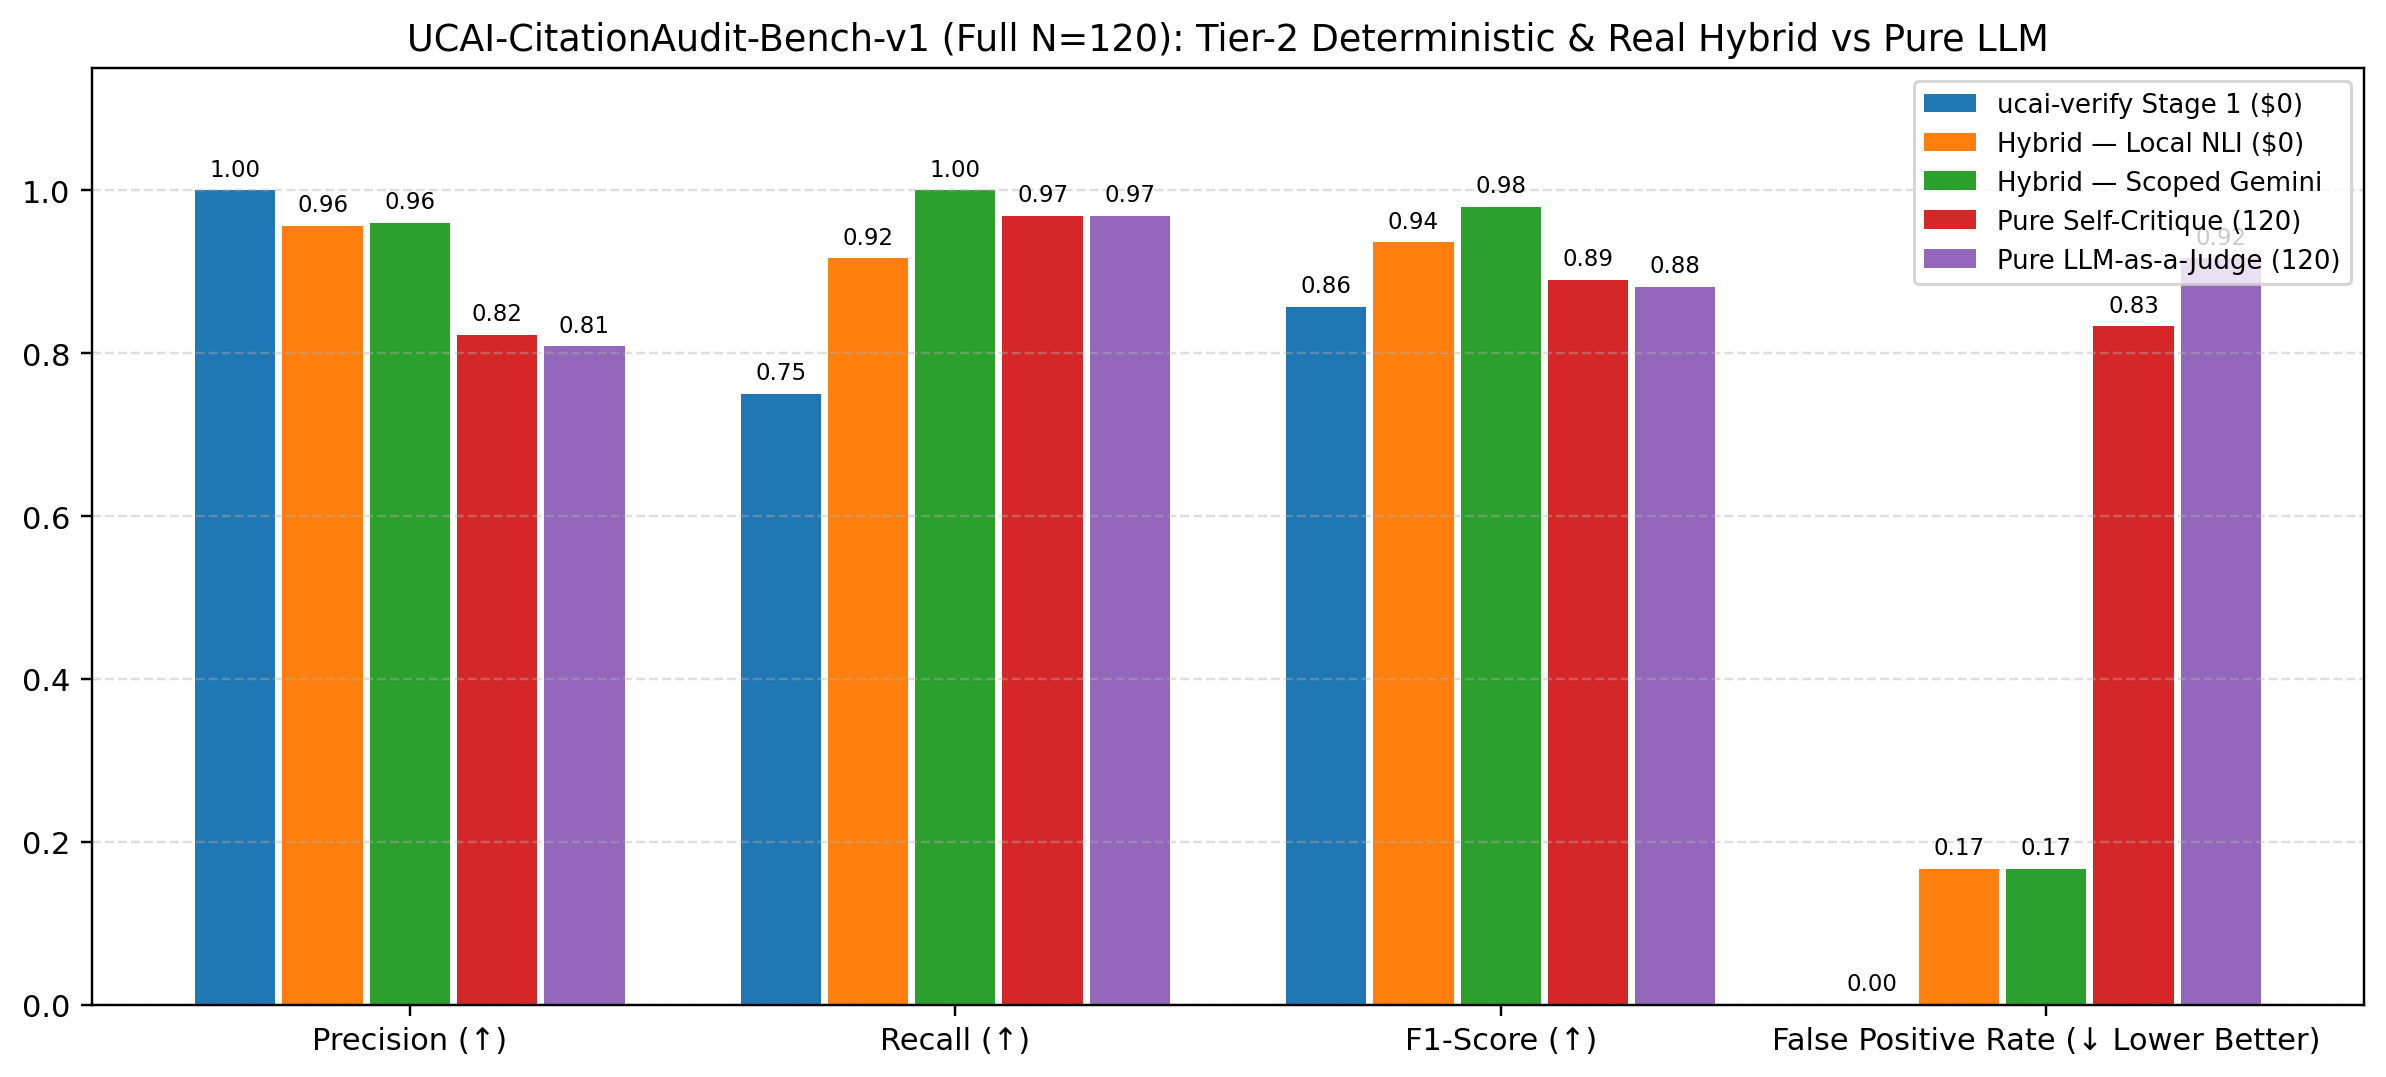


✅ เสร็จสมบูรณ์ 100%! บันทึกไฟล์ผลทดลอง Tier-2 ทั้งหมดลงที่: /content/drive/MyDrive/UCAI-Central-Library/05-Research-Papers-OpenTextbooks/06-Flagship4-Paper1-Workspace/results_tier2
👉 ขั้นตอนต่อไป: กลับไปพิมพ์แจ้งในแชต Antigravity ได้เลยว่า "รัน Colab เฟส 1 เสร็จแล้ว" ครับ!


In [4]:
# @title 4. สรุปตารางผลทดลอง Tier-2, สถิติ McNemar's Test และสร้างกราฟบันทึกลง Google Drive
import json, pandas as pd, matplotlib.pyplot as plt
from ucai_verify.evaluator import mcnemar_exact_pvalue

all_runs = [('ucai-verify Stage 1 ($0)', ucai_res)]
if 'hnli_res' in globals() and hnli_res: all_runs.append(('Hybrid — Local NLI ($0)', hnli_res))
if 'hgem_res' in globals() and hgem_res: all_runs.append(('Hybrid — Scoped Gemini', hgem_res))
if 'sc_res' in globals() and sc_res:     all_runs.append(('Pure Self-Critique (120)', sc_res))
if 'lj_res' in globals() and lj_res:     all_runs.append(('Pure LLM-as-a-Judge (120)', lj_res))

summary_rows = []
per_class_rows = {}
for label, res in all_runs:
    m = res['metrics']
    summary_rows.append({
        'Method': label,
        'N': m.get('n', 120),
        'Clean_OK': m.get('clean_ok', 120),
        'Accuracy': m['accuracy'],
        'Precision': m['precision'],
        'Recall': m['recall'],
        'F1': m['f1'],
        'F1_CI95': str(m.get('f1_ci95', '')),
        'FPR': m['fpr'],
        'FPR_CI95': str(m.get('fpr_ci95', '')),
        'LLM_Calls': m.get('llm_api_calls', 0),
        'Sec_Per_Item': m.get('sec_per_item', 0.0),
    })
    per_class_rows[label] = {cls: v['acc'] for cls, v in res['per_class'].items()}

df_sum = pd.DataFrame(summary_rows)
df_cls = pd.DataFrame(per_class_rows)
df_sum.to_csv(RESULTS_DIR / 'paper1_tier2_comparison_summary.csv', index=False)
df_cls.to_csv(RESULTS_DIR / 'paper1_tier2_per_class.csv')

print('=== ตารางสรุปผลเปรียบเทียบ Tier-2 (Full 120 Items) ===')
display(df_sum)
print('\n=== ความแม่นยำแยกตามประเภทความผิดพลาดทั้ง 5 คลาส ===')
display(df_cls)

stats_out = {}
y_true = [it.is_corrupted for it in items]
if 'lj_res' in globals() and lj_res and len(lj_res['records']) == 120:
    yp_lj = [r['pred_corrupted'] for r in lj_res['records']]
    if 'hnli_res' in globals() and hnli_res:
        stats_out['hnli_vs_llm_judge'] = mcnemar_exact_pvalue(y_true, [r['pred_corrupted'] for r in hnli_res['records']], yp_lj)
    if 'hgem_res' in globals() and hgem_res:
        stats_out['hgem_vs_llm_judge'] = mcnemar_exact_pvalue(y_true, [r['pred_corrupted'] for r in hgem_res['records']], yp_lj)
    stats_out['stage1_vs_llm_judge'] = mcnemar_exact_pvalue(y_true, [r['pred_corrupted'] for r in ucai_res['records']], yp_lj)
(RESULTS_DIR / 'paper1_tier2_stats.json').write_text(json.dumps(stats_out, indent=2), encoding='utf-8')
if stats_out:
    print('\n=== ผลทดสอบนัยสำคัญทางสถิติ (Exact McNemar Test, N=120) ===')
    print(json.dumps(stats_out, indent=2))

fig, ax = plt.subplots(figsize=(11, 5), dpi=220)
metrics_to_plot = ['Precision', 'Recall', 'F1', 'FPR']
x = range(len(metrics_to_plot))
width = 0.8 / max(len(df_sum), 1)
for idx, row in df_sum.iterrows():
    vals = [row[m] for m in metrics_to_plot]
    offset = (idx - (len(df_sum) - 1) / 2) * width
    bars = ax.bar([i + offset for i in x], vals, width=width * 0.92, label=row['Method'])
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.018, f'{b.get_height():.2f}', ha='center', fontsize=7.5)

ax.set_xticks(list(x))
ax.set_xticklabels(['Precision (↑)', 'Recall (↑)', 'F1-Score (↑)', 'False Positive Rate (↓ Lower Better)'])
ax.set_ylim(0, 1.15)
ax.set_title('UCAI-CitationAudit-Bench-v1 (Full N=120): Tier-2 Deterministic & Real Hybrid vs Pure LLM')
ax.legend(loc='upper right', fontsize=8.5)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
fig_path = RESULTS_DIR / 'fig_paper1_tier2_results.png'
plt.savefig(fig_path, dpi=220)
plt.show()
print(f'\n✅ เสร็จสมบูรณ์ 100%! บันทึกไฟล์ผลทดลอง Tier-2 ทั้งหมดลงที่: {RESULTS_DIR}')
print('👉 ขั้นตอนต่อไป: กลับไปพิมพ์แจ้งในแชต Antigravity ได้เลยว่า "รัน Colab เฟส 1 เสร็จแล้ว" ครับ!')